# Fase 3 · Preparación de datos y modelo en estrella
**Evento Evaluativo 3 · Análisis de Datos (ITM, 2026-2) · Grupo 2 · Clientes bancarios**

Aquí convertimos el archivo plano en un modelo de datos listo para Power BI. Seguimos el orden ETL que vimos en la semana 7-8: **Extraer** los datos, **Transformarlos** y **Cargarlos** (en este caso, a archivos que importa Power BI).

Como en las otras fases, primero observamos y después decidimos.

## 1. Qué vamos a construir y por qué

**Lo que vimos en clase, aplicado a este proyecto:**

| Concepto | En nuestro proyecto |
|---|---|
| Base transaccional (OLTP) vs analítica (OLAP) | El archivo original es una foto de la base de clientes del banco, hecha para registrar. Nosotros lo reorganizamos para **consultar y analizar** |
| Data Warehouse | Un almacén de datos integrado, histórico y orientado a decidir. Nuestro mini-almacén son las tablas que exportamos. No es histórico porque el dataset no trae fechas |
| ETL | Extraer (leer el CSV), Transformar (limpiar, nombrar, crear rangos) y Cargar (exportar las tablas) |
| Tabla de hechos | Guarda lo que **medimos**: saldo, salario, puntaje, abandono |
| Tablas de dimensiones | Guardan **cómo miramos** lo medido: por país, por edad, por género... |
| Esquema en estrella | Una tabla de hechos al centro y las dimensiones alrededor, cada una conectada directo a ella |

**Por qué estrella y no copo de nieve:** en el copo de nieve las dimensiones se parten en más tablas (por ejemplo país → región → continente) para no repetir datos. Es más ordenado pero obliga a más relaciones. Nuestras dimensiones son pequeñas y no tienen niveles que repetir, así que la estrella es más simple y Power BI la lee más rápido. Esto también responde a la preocupación de no enredar las relaciones: todas son del mismo tipo.

**Grano de la tabla de hechos:** una fila es **un cliente**. Definirlo primero evita mezclar cosas distintas en la misma tabla.

## 2. Extract · Leer los datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


def ruta_dataset():
    # Busca primero el archivo en la caché de kagglehub (rápido). Si no está, lo descarga.
    base = os.path.expanduser("~/.cache/kagglehub/datasets/mathchi/churn-for-bank-customers/versions")
    if os.path.isdir(base):
        for version in sorted(os.listdir(base), reverse=True):
            carpeta = os.path.join(base, version)
            if os.path.exists(os.path.join(carpeta, "churn.csv")):
                return carpeta
    import kagglehub
    return kagglehub.dataset_download("mathchi/churn-for-bank-customers")


df_raw = pd.read_csv(os.path.join(ruta_dataset(), "churn.csv"))
print("Filas y columnas leídas:", df_raw.shape)
df_raw.head()

Filas y columnas leídas: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Transform · Transformar los datos

### 3.1 Qué hacemos con las columnas que identifican personas
Miramos primero qué es cada una antes de decidir.

In [2]:
print("¿RowNumber es solo el número de fila (1, 2, 3...)?",
      (df_raw["RowNumber"] == np.arange(1, len(df_raw) + 1)).all())
print("¿CustomerId es único?", df_raw["CustomerId"].is_unique)
print("Apellidos distintos:", df_raw["Surname"].nunique(), "de", len(df_raw), "filas")
print()
print("Los apellidos más repetidos:")
print(df_raw["Surname"].value_counts().head(5))

¿RowNumber es solo el número de fila (1, 2, 3...)? True
¿CustomerId es único? True
Apellidos distintos: 2932 de 10000 filas

Los apellidos más repetidos:
Surname
Smith     32
Scott     29
Martin    29
Walker    28
Brown     26
Name: count, dtype: int64


**Lo que se ve:** `RowNumber` es exactamente 1, 2, 3... (el resultado es `True`), así que solo cuenta filas. `CustomerId` es único: ningún cliente aparece dos veces. Hay 2.932 apellidos distintos para 10.000 clientes y el más repetido es Smith, con 32. Por eso el apellido no puede ser llave.

**Decisiones:**
- **`RowNumber`: se descarta.** Solo cuenta filas, no describe al cliente.
- **`CustomerId`: se queda** como llave del cliente. Es único, y sirve para identificar a cada cliente en las listas de detalle y para unir tablas más adelante.
- **`Surname` (apellido): se queda** como dato descriptivo de la tabla de detalle, pero **no es llave** porque se repite entre clientes distintos.

**Nota sobre datos personales:** en un banco real los apellidos son datos personales y habría que protegerlos. Aquí el dataset es público y anonimizado, así que los dejamos solo para la lista de detalle. En los gráficos del dashboard no los mostramos.

### 3.2 Nombres claros y consistentes
Pasamos los nombres a español, sin tildes y en minúsculas con guion bajo, para que se entiendan en Power BI y el video.

In [3]:
nombres = {
    "CustomerId": "id_cliente", "Surname": "apellido", "CreditScore": "puntaje_credito",
    "Geography": "pais", "Gender": "genero", "Age": "edad", "Tenure": "anios_cliente",
    "Balance": "saldo", "NumOfProducts": "num_productos", "HasCrCard": "tiene_tarjeta",
    "IsActiveMember": "es_activo", "EstimatedSalary": "salario_estimado", "Exited": "abandono",
}
clientes = df_raw.drop(columns=["RowNumber"]).rename(columns=nombres)
pd.DataFrame({"antes": list(nombres.keys()), "después": list(nombres.values())})

,antes,después
0,CustomerId,id_cliente
1,Surname,apellido
2,CreditScore,puntaje_credito
3,Geography,pais
4,Gender,genero
5,Age,edad
6,Tenure,anios_cliente
7,Balance,saldo
8,NumOfProducts,num_productos
9,HasCrCard,tiene_tarjeta


### 3.3 Revisar que los valores tengan sentido
Antes de construir nada, comprobamos que no haya valores imposibles. Si algo falla, el código se detiene y avisa.

In [4]:
resumen = clientes.drop(columns=["id_cliente", "apellido"]).agg(["min", "max"]).T
print(resumen)

assert clientes["edad"].between(18, 100).all(), "Hay edades fuera de rango"
assert clientes["anios_cliente"].between(0, 10).all(), "Hay antigüedades fuera de 0-10"
assert (clientes["saldo"] >= 0).all(), "Hay saldos negativos"
assert (clientes["salario_estimado"] > 0).all(), "Hay salarios no positivos"
assert clientes["puntaje_credito"].between(300, 850).all(), "Puntajes fuera del rango 300-850"
assert clientes["num_productos"].between(1, 4).all(), "Productos fuera de 1-4"
for col in ["tiene_tarjeta", "es_activo", "abandono"]:
    assert clientes[col].isin([0, 1]).all(), f"{col} no es 0/1"
print()
print("Todas las revisiones pasaron")

                     min        max
puntaje_credito      350        850
pais              France      Spain
genero            Female       Male
edad                  18         92
anios_cliente          0         10
saldo                0.0  250898.09
num_productos          1          4
tiene_tarjeta          0          1
es_activo              0          1
salario_estimado   11.58  199992.48
abandono               0          1

Todas las revisiones pasaron


**Lo que se ve:** todos los valores tienen sentido: edades de 18 a 92 años, antigüedad de 0 a 10 años, puntajes de crédito de 350 a 850, productos de 1 a 4 y saldos desde 0 hasta unos 251 mil, sin negativos. El salario estimado va de unos 12 a casi 200 mil. Las tres banderas (tarjeta, activo y abandono) solo tienen 0 y 1.

En `pais` y `genero` el mínimo y el máximo salen como `France / Spain` y `Female / Male`: al ser texto, eso es solo el orden alfabético y no significa nada.

### 3.4 Observar la distribución para decidir los rangos
Las dimensiones de rangos (edad, saldo, salario, puntaje, antigüedad) necesitan cortes. Los elegimos mirando los datos y las convenciones, no al azar.

In [5]:
saldo_positivo = clientes.loc[clientes["saldo"] > 0, "saldo"]
print("Clientes con saldo en cero:", (clientes["saldo"] == 0).sum(), "de", len(clientes))
print()
print("Saldo (solo clientes con saldo mayor a cero):")
print(saldo_positivo.describe(percentiles=[1/3, 2/3]).round(0))
print()
print("Salario estimado: de", round(clientes["salario_estimado"].min()), "a", round(clientes["salario_estimado"].max()))
print("Puntaje de crédito: de", clientes["puntaje_credito"].min(), "a", clientes["puntaje_credito"].max())
print("Edad: de", clientes["edad"].min(), "a", clientes["edad"].max())
print("Antigüedad: de", clientes["anios_cliente"].min(), "a", clientes["anios_cliente"].max(), "años")

Clientes con saldo en cero: 3617 de 10000

Saldo (solo clientes con saldo mayor a cero):
count      6383.0
mean     119827.0
std       30095.0
min        3769.0
33.3%    107138.0
66.7%    132122.0
max      250898.0
Name: saldo, dtype: float64

Salario estimado: de 12 a 199992
Puntaje de crédito: de 350 a 850
Edad: de 18 a 92
Antigüedad: de 0 a 10 años


**Decisiones sobre los rangos:**
- **Edad:** 18-30, 31-40, 41-50, 51-60 y 61+ (hay clientes de 18 a 92 años). Son los mismos rangos de la exploración de productos y, como en la Fase 2 vimos que el abandono sube entre los 41 y los 60 años y baja después, necesitamos ver ese pico.
- **Saldo:** 3.617 clientes (36,2 %) tienen saldo cero, así que ese es su propio grupo ("Sin saldo"). Los otros 6.383 se dividen en tres partes iguales con los cortes que calculamos: **hasta 107.138** (bajo), **de 107.138 a 132.122** (medio) y **más de 132.122** (alto).
- **Salario estimado:** va de 12 a 199.992, así que cuatro tramos de 50 mil cubren todo el rango.
- **Puntaje de crédito:** va de 350 a 850. Usamos los rangos comunes de los puntajes tipo FICO: pobre (menos de 580), regular, bueno, muy bueno y excelente (800 o más). Es una convención externa, no algo que midió el banco.
- **Antigüedad:** 0-2, 3-5 y 6-10 años (el máximo es 10).

### 3.5 Construir las dimensiones
Cada dimensión tiene una **llave numérica** (`id_...`) y las descripciones que usaremos en filtros y gráficos. Las llaves enteras hacen que Power BI relacione rápido y sin ambigüedad.

In [6]:
# País
dim_geografia = pd.DataFrame({
    "id_geografia": [1, 2, 3],
    "pais": ["Francia", "Alemania", "España"],
    "pais_original": ["France", "Germany", "Spain"],
})
assert set(clientes["pais"].unique()) == set(dim_geografia["pais_original"])

# Género
dim_genero = pd.DataFrame({
    "id_genero": [1, 2],
    "genero": ["Mujer", "Hombre"],
    "genero_original": ["Female", "Male"],
})
assert set(clientes["genero"].unique()) == set(dim_genero["genero_original"])

# Edad
dim_edad = pd.DataFrame({
    "id_edad": [1, 2, 3, 4, 5],
    "rango_edad": ["18-30", "31-40", "41-50", "51-60", "61+"],
})

# Antigüedad
dim_antiguedad = pd.DataFrame({
    "id_antiguedad": [1, 2, 3],
    "rango_antiguedad": ["0-2 años", "3-5 años", "6-10 años"],
})

# Puntaje de crédito
dim_score = pd.DataFrame({
    "id_score": [1, 2, 3, 4, 5],
    "rango_score": ["Pobre (menos de 580)", "Regular (580-669)", "Bueno (670-739)",
                    "Muy bueno (740-799)", "Excelente (800 o más)"],
})

# Saldo: cero aparte y el resto en tres partes iguales
corte_bajo, corte_alto = saldo_positivo.quantile([1/3, 2/3])
dim_saldo = pd.DataFrame({
    "id_saldo": [1, 2, 3, 4],
    "rango_saldo": ["Sin saldo", "Saldo bajo", "Saldo medio", "Saldo alto"],
    "detalle_saldo": ["0", f"hasta {corte_bajo:,.0f}",
                      f"{corte_bajo:,.0f} a {corte_alto:,.0f}", f"más de {corte_alto:,.0f}"],
})

# Salario estimado
dim_salario = pd.DataFrame({
    "id_salario": [1, 2, 3, 4],
    "rango_salario": ["Hasta 50 mil", "50 a 100 mil", "100 a 150 mil", "Más de 150 mil"],
})

# Productos
dim_productos = pd.DataFrame({
    "id_productos": [1, 2, 3, 4],
    "productos": ["1 producto", "2 productos", "3 productos", "4 productos"],
    "grupo_productos": ["1 producto", "2 productos", "3 o 4 productos", "3 o 4 productos"],
})

# Uso: junta dos datos de sí/no (actividad y tarjeta) en una sola tabla pequeña
dim_actividad = pd.DataFrame({
    "id_actividad": [1, 2, 3, 4],
    "es_activo": [1, 1, 0, 0],
    "tiene_tarjeta": [1, 0, 1, 0],
})
dim_actividad["estado_actividad"] = dim_actividad["es_activo"].map({1: "Activo", 0: "Inactivo"})
dim_actividad["tarjeta_credito"] = dim_actividad["tiene_tarjeta"].map({1: "Con tarjeta", 0: "Sin tarjeta"})
dim_actividad["perfil_uso"] = dim_actividad["estado_actividad"] + " · " + dim_actividad["tarjeta_credito"]

# Estado del cliente
dim_estado = pd.DataFrame({"id_estado": [1, 2], "estado": ["Sigue", "Se fue"]})

dimensiones = {
    "dim_geografia": dim_geografia, "dim_genero": dim_genero, "dim_edad": dim_edad,
    "dim_antiguedad": dim_antiguedad, "dim_score": dim_score, "dim_saldo": dim_saldo,
    "dim_salario": dim_salario, "dim_productos": dim_productos,
    "dim_actividad": dim_actividad, "dim_estado": dim_estado,
}
dim_saldo

,id_saldo,rango_saldo,detalle_saldo
0,1,Sin saldo,0
1,2,Saldo bajo,"hasta 107,138"
2,3,Saldo medio,"107,138 a 132,122"
3,4,Saldo alto,"más de 132,122"


**Sobre la dimensión de uso (`dim_actividad`):** juntamos "activo" y "tiene tarjeta" en una sola tabla de cuatro filas (una dimensión de este tipo se llama *junk dimension*, o de "banderas"). Así no creamos dos tablas diminutas de dos filas cada una.

### 3.6 Construir la tabla de hechos
Cada cliente recibe la llave de cada dimensión según sus datos. Conservamos también los valores originales (edad, saldo, salario, puntaje), porque son las **medidas** con las que haremos promedios y sumas.

In [7]:
fact = pd.DataFrame({"id_cliente": clientes["id_cliente"], "apellido": clientes["apellido"]})

fact["id_geografia"] = clientes["pais"].map(dict(zip(dim_geografia["pais_original"], dim_geografia["id_geografia"])))
fact["id_genero"] = clientes["genero"].map(dict(zip(dim_genero["genero_original"], dim_genero["id_genero"])))

fact["id_edad"] = pd.cut(clientes["edad"], bins=[17, 30, 40, 50, 60, 200], labels=dim_edad["id_edad"]).astype(int)
fact["id_antiguedad"] = pd.cut(clientes["anios_cliente"], bins=[-1, 2, 5, 10], labels=dim_antiguedad["id_antiguedad"]).astype(int)
fact["id_score"] = pd.cut(clientes["puntaje_credito"], bins=[0, 579, 669, 739, 799, 1000], labels=dim_score["id_score"]).astype(int)
fact["id_salario"] = pd.cut(clientes["salario_estimado"], bins=[0, 50000, 100000, 150000, 1e12], labels=dim_salario["id_salario"]).astype(int)

fact["id_saldo"] = np.select(
    [clientes["saldo"] == 0, clientes["saldo"] <= corte_bajo, clientes["saldo"] <= corte_alto],
    [1, 2, 3], default=4)

fact["id_productos"] = clientes["num_productos"]

pares = list(zip(dim_actividad["es_activo"], dim_actividad["tiene_tarjeta"]))
mapa_actividad = dict(zip(pares, dim_actividad["id_actividad"]))
fact["id_actividad"] = [mapa_actividad[p] for p in zip(clientes["es_activo"], clientes["tiene_tarjeta"])]

fact["id_estado"] = clientes["abandono"] + 1

# Medidas
fact["edad"] = clientes["edad"]
fact["anios_cliente"] = clientes["anios_cliente"]
fact["puntaje_credito"] = clientes["puntaje_credito"]
fact["saldo"] = clientes["saldo"]
fact["salario_estimado"] = clientes["salario_estimado"]
fact["num_productos"] = clientes["num_productos"]
fact["abandono"] = clientes["abandono"]

fact.head()

,id_cliente,apellido,id_geografia,id_genero,id_edad,id_antiguedad,id_score,id_salario,id_saldo,id_productos,id_actividad,id_estado,edad,anios_cliente,puntaje_credito,saldo,salario_estimado,num_productos,abandono
0,15634602,Hargrave,1,1,3,1,2,3,1,1,1,2,42,2,619,0.00,101348.88,1,1
1,15647311,Hill,3,1,3,1,2,3,2,1,2,1,41,1,608,83807.86,112542.58,1,0
2,15619304,Onio,1,1,3,3,1,3,4,3,3,2,42,8,502,159660.80,113931.57,3,1
3,15701354,Boni,1,1,2,1,3,2,1,2,4,1,39,1,699,0.00,93826.63,2,0
4,15737888,Mitchell,3,1,3,1,5,2,3,1,1,1,43,2,850,125510.82,79084.10,1,0


### 3.7 Comprobar que no perdimos ni inventamos nada
Esta revisión es lo que da confianza al modelo. Verificamos que cada cliente encuentre su pareja en cada dimensión y que los totales coincidan con el archivo original.

In [8]:
for nombre, dim in dimensiones.items():
    llave = dim.columns[0]
    assert dim[llave].is_unique, f"{llave} repetida en {nombre}"
    assert fact[llave].notna().all(), f"hay clientes sin {llave}"
    assert fact[llave].isin(dim[llave]).all(), f"hay clientes sin pareja en {nombre}"
    print(f"{nombre:<16} llave {llave:<14} filas en la dimensión: {len(dim):>2} | clientes sin pareja: 0")

print()
assert len(fact) == len(df_raw), "cambió el número de filas"
assert fact["id_cliente"].is_unique, "hay clientes repetidos"
assert np.isclose(fact["abandono"].mean(), df_raw["Exited"].mean()), "cambió la tasa de abandono"
assert np.isclose(fact["saldo"].sum(), df_raw["Balance"].sum()), "cambió el saldo total"
por_pais = fact.merge(dim_geografia, on="id_geografia").groupby("pais_original").size().sort_index().to_dict()
assert por_pais == df_raw["Geography"].value_counts().sort_index().to_dict(), "cambió el conteo por país"

print("Filas:", len(fact), "(igual que el original)")
print("Tasa de abandono:", round(fact["abandono"].mean() * 100, 1), "% (igual que el original)")
print("Saldo total:", f"{fact['saldo'].sum():,.0f}", "(igual que el original)")
print("Clientes por país:", por_pais, "(igual que el original)")

dim_geografia    llave id_geografia   filas en la dimensión:  3 | clientes sin pareja: 0
dim_genero       llave id_genero      filas en la dimensión:  2 | clientes sin pareja: 0
dim_edad         llave id_edad        filas en la dimensión:  5 | clientes sin pareja: 0
dim_antiguedad   llave id_antiguedad  filas en la dimensión:  3 | clientes sin pareja: 0
dim_score        llave id_score       filas en la dimensión:  5 | clientes sin pareja: 0
dim_saldo        llave id_saldo       filas en la dimensión:  4 | clientes sin pareja: 0
dim_salario      llave id_salario     filas en la dimensión:  4 | clientes sin pareja: 0
dim_productos    llave id_productos   filas en la dimensión:  4 | clientes sin pareja: 0
dim_actividad    llave id_actividad   filas en la dimensión:  4 | clientes sin pareja: 0
dim_estado       llave id_estado      filas en la dimensión:  2 | clientes sin pareja: 0

Filas: 10000 (igual que el original)
Tasa de abandono: 20.4 % (igual que el original)
Saldo total: 764,858,89

**Lo que se ve:** cada uno de los 10.000 clientes encontró su pareja en las diez dimensiones (0 clientes sin pareja). Los totales coinciden con el archivo original: 10.000 filas, 20,4 % de abandono, saldo total de 764.858.893 y, por país, 5.014 en Francia, 2.509 en Alemania y 2.477 en España. No se perdió ni se inventó nada, y eso es lo que da confianza al modelo.

## 4. Load · Cargar (exportar las tablas)
Guardamos cada tabla como CSV en `data/processed/`. Power BI importa esos archivos. Usamos la codificación UTF-8 con marca (`utf-8-sig`) para que las tildes se vean bien al abrirlos en Power BI o en Excel.

In [9]:
carpeta_salida = os.path.join("..", "data", "processed")
os.makedirs(carpeta_salida, exist_ok=True)

tablas = {"fact_clientes": fact, **dimensiones}
for nombre, tabla in tablas.items():
    tabla.to_csv(os.path.join(carpeta_salida, f"{nombre}.csv"), index=False, encoding="utf-8-sig")

pd.DataFrame({"tabla": list(tablas.keys()),
              "filas": [len(t) for t in tablas.values()],
              "columnas": [t.shape[1] for t in tablas.values()]})

,tabla,filas,columnas
0,fact_clientes,10000,19
1,dim_geografia,3,3
2,dim_genero,2,3
3,dim_edad,5,2
4,dim_antiguedad,3,2
5,dim_score,5,2
6,dim_saldo,4,3
7,dim_salario,4,2
8,dim_productos,4,3
9,dim_actividad,4,6


**Lo que se ve:** se exportaron 11 tablas. La de hechos tiene 10.000 filas y 19 columnas; las dimensiones tienen entre 2 y 5 filas. `dim_actividad` tiene 6 columnas porque guarda los valores de sí/no y también sus etiquetas. Son tablas pequeñas, así que Power BI las carga al instante.

### Diccionario de datos
Un archivo que explica cada columna de cada tabla. También se exporta, para que cualquiera que abra el modelo entienda qué es cada cosa.

In [10]:
descripciones = {
    "id_cliente": "Código del cliente en el banco",
    "apellido": "Apellido del cliente (dato descriptivo, no es llave)",
    "id_geografia": "Llave del país", "pais": "País del cliente", "pais_original": "País como venía en el dataset",
    "id_genero": "Llave del género", "genero": "Género del cliente", "genero_original": "Género como venía en el dataset",
    "id_edad": "Llave del rango de edad", "rango_edad": "Rango de edad en años",
    "id_antiguedad": "Llave del rango de antigüedad", "rango_antiguedad": "Rango de años como cliente",
    "id_score": "Llave del rango de puntaje de crédito", "rango_score": "Rango de puntaje de crédito (convención tipo FICO)",
    "id_saldo": "Llave del rango de saldo", "rango_saldo": "Grupo de saldo (cero, bajo, medio, alto)", "detalle_saldo": "Límites del grupo de saldo",
    "id_salario": "Llave del rango de salario", "rango_salario": "Tramo de salario estimado",
    "id_productos": "Llave de la cantidad de productos", "productos": "Cantidad de productos que tiene el cliente",
    "grupo_productos": "Agrupación de productos: 1, 2 o 3 o 4",
    "id_actividad": "Llave del perfil de uso", "es_activo": "1 si el cliente es activo, 0 si no",
    "tiene_tarjeta": "1 si tiene tarjeta de crédito, 0 si no", "estado_actividad": "Activo o inactivo",
    "tarjeta_credito": "Con o sin tarjeta", "perfil_uso": "Combinación de actividad y tarjeta",
    "id_estado": "Llave del estado del cliente", "estado": "Sigue o Se fue",
    "edad": "Edad del cliente en años", "anios_cliente": "Años que lleva como cliente",
    "puntaje_credito": "Puntaje de crédito", "saldo": "Saldo en la cuenta", "salario_estimado": "Salario estimado",
    "num_productos": "Cantidad de productos del banco que tiene",
    "abandono": "1 si el cliente se fue del banco, 0 si sigue",
}

filas = []
for nombre, tabla in tablas.items():
    for col in tabla.columns:
        if nombre.startswith("dim_") and col == tabla.columns[0]:
            rol = "Llave primaria"
        elif col == "id_cliente":
            rol = "Identificador del cliente"
        elif nombre == "fact_clientes" and col.startswith("id_"):
            rol = "Llave foránea"
        elif nombre == "fact_clientes" and pd.api.types.is_numeric_dtype(tabla[col]):
            rol = "Medida"
        else:
            rol = "Atributo"
        filas.append({"tabla": nombre, "columna": col, "tipo": str(tabla[col].dtype),
                      "rol": rol, "descripcion": descripciones.get(col, "")})

diccionario = pd.DataFrame(filas)
diccionario.to_csv(os.path.join(carpeta_salida, "diccionario_datos.csv"), index=False, encoding="utf-8-sig")
print("Columnas sin descripción:", (diccionario["descripcion"] == "").sum())
diccionario

Columnas sin descripción: 0


,tabla,columna,tipo,rol,descripcion
0,fact_clientes,id_cliente,int64,Identificador del cliente,Código del cliente en el banco
1,fact_clientes,apellido,str,Atributo,"Apellido del cliente (dato descriptivo, no es ..."
2,fact_clientes,id_geografia,int64,Llave foránea,Llave del país
3,fact_clientes,id_genero,int64,Llave foránea,Llave del género
4,fact_clientes,id_edad,int64,Llave foránea,Llave del rango de edad
5,fact_clientes,id_antiguedad,int64,Llave foránea,Llave del rango de antigüedad
6,fact_clientes,id_score,int64,Llave foránea,Llave del rango de puntaje de crédito
7,fact_clientes,id_salario,int64,Llave foránea,Llave del rango de salario
8,fact_clientes,id_saldo,int64,Llave foránea,Llave del rango de saldo
9,fact_clientes,id_productos,int64,Llave foránea,Llave de la cantidad de productos


## 5. El modelo en estrella

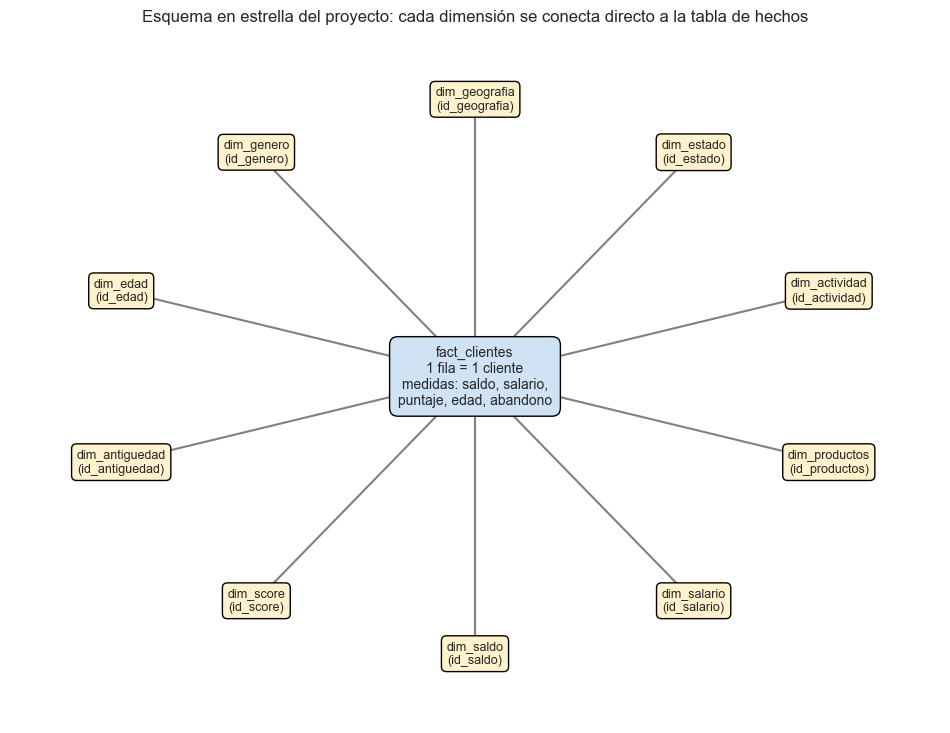

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

centro = (0.5, 0.5)
angulos = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, len(dimensiones), endpoint=False)
for (nombre, dim), a in zip(dimensiones.items(), angulos):
    x, y = 0.5 + 0.40 * np.cos(a), 0.5 + 0.40 * np.sin(a)
    ax.plot([centro[0], x], [centro[1], y], color="gray", zorder=1)
    ax.text(x, y, f"{nombre}\n({dim.columns[0]})", ha="center", va="center", fontsize=9, zorder=2,
            bbox=dict(boxstyle="round,pad=0.4", fc="#fff2cc", ec="black"))

ax.text(*centro, "fact_clientes\n1 fila = 1 cliente\nmedidas: saldo, salario,\npuntaje, edad, abandono",
        ha="center", va="center", fontsize=10, zorder=3,
        bbox=dict(boxstyle="round,pad=0.6", fc="#cfe3f5", ec="black"))
ax.set_title("Esquema en estrella del proyecto: cada dimensión se conecta directo a la tabla de hechos")
plt.show()

**Relaciones del modelo.** Todas son iguales, y eso es lo que mantiene el modelo simple:

| Dimensión (lado 1) | Llave | Tabla de hechos (lado muchos) | Cardinalidad | Dirección del filtro |
|---|---|---|---|---|
| dim_geografia | id_geografia | fact_clientes | uno a muchos | de la dimensión hacia los hechos |
| dim_genero | id_genero | fact_clientes | uno a muchos | igual |
| dim_edad | id_edad | fact_clientes | uno a muchos | igual |
| dim_antiguedad | id_antiguedad | fact_clientes | uno a muchos | igual |
| dim_score | id_score | fact_clientes | uno a muchos | igual |
| dim_saldo | id_saldo | fact_clientes | uno a muchos | igual |
| dim_salario | id_salario | fact_clientes | uno a muchos | igual |
| dim_productos | id_productos | fact_clientes | uno a muchos | igual |
| dim_actividad | id_actividad | fact_clientes | uno a muchos | igual |
| dim_estado | id_estado | fact_clientes | uno a muchos | igual |

**Convenciones de nombres:** `fact_` para la tabla de hechos y `dim_` para las dimensiones. Las llaves se llaman `id_` más el nombre de la dimensión y se llaman **igual** en las dos tablas, así Power BI detecta la relación solo.

## 6. Importar a Power BI (guía para la Fase 5)
1. En Power BI Desktop: **Obtener datos → Texto o CSV** y selecciona los 11 archivos de `data/processed/` (la tabla de hechos y las 10 dimensiones). El diccionario no hace falta importarlo.
2. En la vista **Modelo**, comprueba que existan 10 relaciones, de **uno a varios** (1:*), con filtro en **una sola dirección**. Si alguna no se creó sola, arrastra la llave `id_...` de la dimensión a la de la tabla de hechos.
3. En cada dimensión, marca las columnas `id_...` como **no resumir** y **ocúltalas** de la vista de informe, para que no aparezcan como campos de uso.
4. Para que los rangos salgan en orden y no alfabético, en cada dimensión usa **Ordenar por columna** y elige su `id_...` (por ejemplo, `rango_edad` ordenado por `id_edad`).
5. Oculta también `pais_original` y `genero_original`, que solo sirven para trazabilidad.
6. Las medidas (tasa de abandono, saldo en riesgo, etc.) se crean en la Fase 4 en una tabla aparte llamada `_Medidas`.

## 7. Cierre de la Fase 3
| Requisito | Dónde |
|---|---|
| Limpieza y transformación documentadas | Secciones 3.1 a 3.3 |
| Selección de variables justificada | Sección 3.1 (qué se descarta y qué se queda) |
| Dimensiones y métricas definidas | Secciones 3.4 a 3.6 |
| Datos estructurados (modelo en estrella) | Secciones 3.5, 3.6 y 5 |
| ETL: extraer, transformar, cargar | Secciones 2, 3 y 4 |
| Datos de calidad comprobados | Secciones 3.3 y 3.7 |
| Conceptos de la semana 7-8 (OLTP/OLAP, hechos y dimensiones, estrella vs copo de nieve) | Sección 1 |

**Lo que sigue:** en la Fase 4 definimos los indicadores (KPIs), las medidas de Power BI y el modelo de riesgo que da un puntaje de probabilidad de abandono a cada cliente.